# Hypothesis Testing Beyond the Basics

**What you'll learn**

- Why Welch's t-test should be your default two-sample test — and the exact configurations
  of sample sizes and variances where Student's t over-rejects by 5x or silently loses power.
- How to implement a permutation test for *any* statistic (means, medians, whatever your
  business cares about), why it is finite-sample exact, and its one important caveat.
- What Mann–Whitney actually tests (stochastic dominance, **not** medians) — including a
  dataset where it is wildly significant while the means are identical.
- Proportion tests done properly: the z-test/χ² equivalence, confidence intervals for
  absolute and relative lift (log transform for the ratio), and how small samples break the
  normal approximation.
- How to keep statistical and practical significance separate: effect sizes, and a
  p < 10⁻⁶ result you should probably not ship.
- What p-values actually are as random variables — uniform under H0, right-skewed under an
  alternative — and a base-rate simulation showing why p is **not** P(H0 | data).

**Why it matters in interviews**

- "Which test would you use here, and why?" is the most common statistics screen for senior
  DS roles. The senior answer names assumptions and *failure modes*, not just test names.
- Experiment-review rounds probe whether you conflate significance with importance; the
  tiny-effect-at-huge-n case ("p < 1e-6, ship it?") is a staple.
- "Explain a p-value to a PM" is a classic communication test — most candidates fail it by
  saying "the probability the null is true."
- Nonparametric questions are often traps: interviewers check whether you know that
  Mann–Whitney is not a median test and that permutation tests test a *sharp* null.

This notebook builds on the sampling distributions and bootstrap machinery from
[01_sampling_clt_bootstrap.ipynb](./01_sampling_clt_bootstrap.ipynb). Multiple testing and
p-hacking live in [04_statistical_traps.ipynb](./04_statistical_traps.ipynb); experiment
*design* (power, MDE, sequential monitoring) lives in
[../02_ab_testing/](../02_ab_testing/02_power_mde_sample_size.ipynb).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest

rng = np.random.default_rng(42)

plt.rcParams.update({
    "figure.figsize": (8.0, 4.2),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.autolayout": True,
})
pd.set_option("display.precision", 4)

## 1. Welch vs Student: stop pooling variances

Both tests compare two means; they differ only in the standard error of the difference.

- **Student** pools the two sample variances into one estimate and uses
  $SE^2 = s_p^2 (1/n_1 + 1/n_2)$. Valid only if the population variances are equal.
- **Welch** uses $SE^2 = s_1^2/n_1 + s_2^2/n_2$ with Welch–Satterthwaite degrees of
  freedom. Valid whether or not the variances are equal (the Behrens–Fisher problem).

The failure mode of Student's t is not symmetric — it depends on *which* group is noisier:

- **Small group has the larger variance** → the pooled estimate is dominated by the big,
  quiet group → SE is *underestimated* → the test **over-rejects** (anti-conservative:
  your false-positive rate silently exceeds α).
- **Large group has the larger variance** → SE is *overestimated* → the test
  **under-rejects** (conservative: you burn power without knowing it).

In product experiments unequal variances are the norm, not the exception (treatment often
changes the variance of engagement/spend, and ramp-up designs give unequal n). Let's
measure the *empirical type I error* ("size") of both tests under H0 in three scenarios.

In [2]:
def t_test_size(n1, sd1, n2, sd2, n_sims=30_000, alpha=0.05):
    """Empirical type-I error of Student vs Welch t under H0 (both means equal)."""
    a = rng.normal(0.0, sd1, size=(n_sims, n1))
    b = rng.normal(0.0, sd2, size=(n_sims, n2))
    p_student = stats.ttest_ind(a, b, axis=1, equal_var=True).pvalue
    p_welch = stats.ttest_ind(a, b, axis=1, equal_var=False).pvalue
    return (p_student < alpha).mean(), (p_welch < alpha).mean()

scenarios = [
    ("balanced, equal SDs (n=50/50, sd=1/1)",     50, 1.0,  50, 1.0),
    ("SMALL group noisier (n=20/100, sd=3/1)",    20, 3.0, 100, 1.0),
    ("LARGE group noisier (n=100/20, sd=3/1)",   100, 3.0,  20, 1.0),
]
rows = []
for label, n1, sd1, n2, sd2 in scenarios:
    size_s, size_w = t_test_size(n1, sd1, n2, sd2)
    rows.append({"scenario": label, "Student t size": size_s, "Welch t size": size_w})
size_df = pd.DataFrame(rows).set_index("scenario")
print("Empirical type-I error at nominal alpha = 0.05 (30,000 sims each):\n")
print(size_df.round(4))

Empirical type-I error at nominal alpha = 0.05 (30,000 sims each):

                                        Student t size  Welch t size
scenario                                                            
balanced, equal SDs (n=50/50, sd=1/1)           0.0511        0.0510
SMALL group noisier (n=20/100, sd=3/1)          0.2862        0.0511
LARGE group noisier (n=100/20, sd=3/1)          0.0005        0.0506


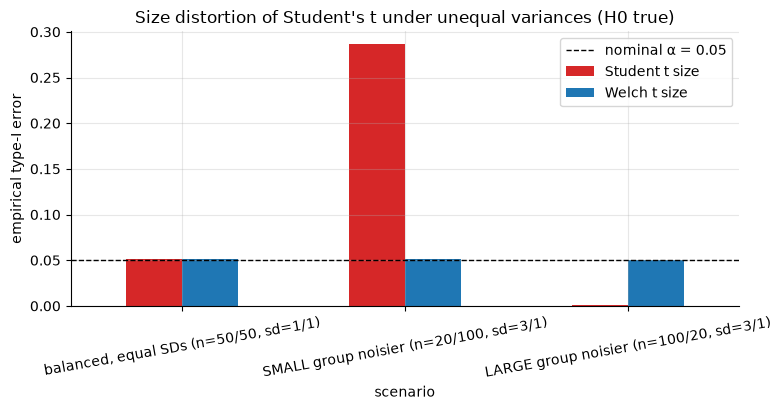

In [3]:
ax = size_df.plot.bar(rot=10, color=["tab:red", "tab:blue"])
ax.axhline(0.05, color="black", ls="--", lw=1, label="nominal α = 0.05")
ax.set_ylabel("empirical type-I error")
ax.set_title("Size distortion of Student's t under unequal variances (H0 true)")
ax.legend()
plt.show()

When the *small* group carries the large variance, Student's t rejects a true null roughly
**five to six times** more often than advertised (~28% vs the nominal 5% here). In the
mirrored scenario it rejects almost never (~0.05%) — you'd need a much larger true effect to
detect anything, and you'd never know why. Welch sits at ≈5% in every scenario, and when
variances *are* equal it costs essentially nothing (a handful of degrees of freedom).

**The senior position:** use Welch by default (`equal_var=False`; it *is* the default in
R's `t.test` for exactly this reason). Do **not** run a variance pre-test (Levene/F) to
decide between them — we'll demonstrate why that two-stage procedure is broken in the
Pitfalls section.

## 2. Permutation tests: the universal tool

If the null hypothesis is "treatment made no difference *at all*" — formally, the group
labels are **exchangeable** — then under H0 every reshuffling of the labels was equally
likely to produce the data we saw. So:

1. compute your statistic on the real labeling,
2. recompute it under many random relabelings,
3. the p-value is the fraction of relabelings at least as extreme as the observed one.

**The exactness idea.** If you enumerated *all* $\binom{n_1+n_2}{n_1}$ relabelings, the
p-value would be exactly valid at any sample size — no normality, no large-n approximation.
With Monte Carlo sampling of B permutations you keep that guarantee by counting the
observed labeling as one of the permutations: $p = (1 + \#\{|T_b| \ge |T_{obs}|\})/(B+1)$.
That "+1" is not cosmetic; without it the p-value can be 0 and the test is invalid.

**Why it's powerful:** the statistic can be *anything* — difference in means, medians,
trimmed means, 90th percentiles, a ratio — including quantities with no textbook test.

Scenario: an 80-user pricing pilot measuring revenue per user — small n, heavy right tail
(classic lognormal spend). True effect: treatment multiplies spend by 1.6x.

In [4]:
def perm_test(x, y, stat, n_perm=9_999, rng=rng):
    """Two-sample permutation test (two-sided).

    `stat(a, b)` must accept 2-D arrays and reduce along axis=-1, e.g.
    lambda a, b: a.mean(axis=-1) - b.mean(axis=-1). Returns (observed stat,
    p-value with the +1 finite-sample correction, permutation distribution).
    """
    x, y = np.asarray(x, float), np.asarray(y, float)
    obs = stat(x[None, :], y[None, :])[0]
    pooled = np.concatenate([x, y])
    perms = rng.permuted(np.tile(pooled, (n_perm, 1)), axis=1)
    t_perm = stat(perms[:, : x.size], perms[:, x.size:])
    p = (1 + np.sum(np.abs(t_perm) >= np.abs(obs))) / (n_perm + 1)
    return obs, p, t_perm


def mean_diff(a, b):
    return a.mean(axis=-1) - b.mean(axis=-1)


def median_diff(a, b):
    return np.median(a, axis=-1) - np.median(b, axis=-1)


n_c, n_t = 40, 40
rev_control = rng.lognormal(mean=np.log(60), sigma=0.7, size=n_c)
rev_treat = rng.lognormal(mean=np.log(60) + np.log(1.6), sigma=0.7, size=n_t)

obs_mean, p_perm_mean, _ = perm_test(rev_treat, rev_control, mean_diff)
p_welch = stats.ttest_ind(rev_treat, rev_control, equal_var=False).pvalue
obs_med, p_perm_med, perm_dist_med = perm_test(rev_treat, rev_control, median_diff)

print(f"control: n={n_c}, mean=${rev_control.mean():,.0f}, median=${np.median(rev_control):,.0f}")
print(f"treat:   n={n_t}, mean=${rev_treat.mean():,.0f}, median=${np.median(rev_treat):,.0f}\n")
print(f"difference in MEANS   : ${obs_mean:,.0f}   permutation p = {p_perm_mean:.4f}"
      f"   (Welch t p = {p_welch:.4f})")
print(f"difference in MEDIANS : ${obs_med:,.0f}   permutation p = {p_perm_med:.4f}"
      f"   (no classical test exists)")

control: n=40, mean=$84, median=$66
treat:   n=40, mean=$120, median=$89

difference in MEANS   : $36   permutation p = 0.0615   (Welch t p = 0.0663)
difference in MEDIANS : $23   permutation p = 0.0367   (no classical test exists)


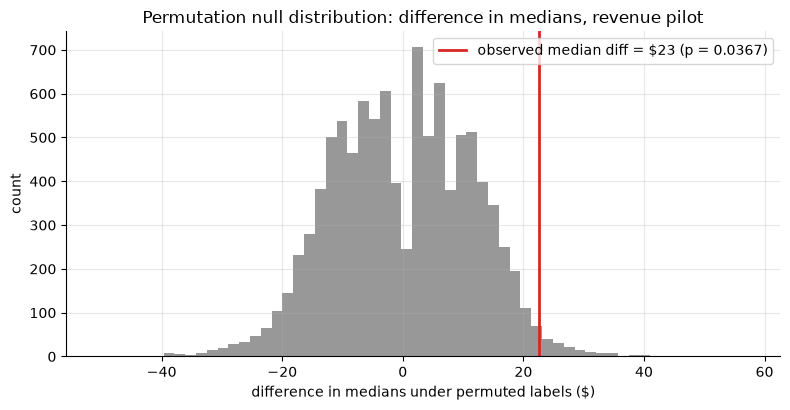

In [5]:
fig, ax = plt.subplots()
ax.hist(perm_dist_med, bins=60, color="tab:gray", alpha=0.8)
ax.axvline(obs_med, color="tab:red", lw=2,
           label=f"observed median diff = ${obs_med:,.0f} (p = {p_perm_med:.4f})")
ax.set_xlabel("difference in medians under permuted labels ($)")
ax.set_ylabel("count")
ax.set_title("Permutation null distribution: difference in medians, revenue pilot")
ax.legend()
plt.show()

The mean-difference permutation p-value lands right next to Welch's — reassuring, since
with 40 per arm and heavy tails the t approximation is the one on shaky ground. More
interesting: the **median** difference — a statistic with no classical two-sample test —
gets a perfectly valid p-value, and here it's the *more decisive* readout: with lognormal
spend, the median is a lower-variance location summary than the tail-dominated mean.

**Verifying exactness.** A test is only as good as its type-I error. Below we run the
permutation test on hundreds of *null* datasets drawn from a nasty skewed distribution at
n=12 per arm, and check it rejects ≈5% of the time.

In [6]:
n_datasets, n_each, n_perm = 500, 12, 999
rej_perm = 0
p_welch_null = np.empty(n_datasets)
for i in range(n_datasets):
    x = rng.lognormal(0.0, 1.0, n_each)
    y = rng.lognormal(0.0, 1.0, n_each)
    _, p, _ = perm_test(x, y, mean_diff, n_perm=n_perm)
    rej_perm += p <= 0.05
    p_welch_null[i] = stats.ttest_ind(x, y, equal_var=False).pvalue

mc_se = np.sqrt(0.05 * 0.95 / n_datasets)
print(f"lognormal null, n={n_each} per arm, {n_datasets} datasets (MC se ≈ {mc_se:.3f}):")
print(f"  permutation test rejection rate: {rej_perm / n_datasets:.3f}")
print(f"  Welch t        rejection rate: {(p_welch_null < 0.05).mean():.3f}")

lognormal null, n=12 per arm, 500 datasets (MC se ≈ 0.010):
  permutation test rejection rate: 0.044
  Welch t        rejection rate: 0.022


The permutation test rejects at ≈5%, as the exactness argument promises — for *any*
distribution, at *any* n. Welch's t is not anti-conservative here, but it rejects at only
~2% — with heavy-tailed data at n=12 the two-sided t is visibly conservative, which means
it is silently *burning power*. Only the permutation test carries a finite-sample
guarantee, and it keeps that guarantee for statistics the t-test can't touch.

**When to prefer a permutation test**

- Small samples with non-normal data, where CLT-based approximations are in doubt.
- Statistics without classical tests: medians, trimmed means, quantiles, custom KPIs.
- When you want an assumption story that survives scrutiny ("exact under exchangeability").

**The caveat (interview favorite):** the permutation null is the **sharp null** — the two
distributions are *identical*, not merely equal in means. If variances differ between
groups but means are equal, label exchange is not distribution-preserving and the
mean-difference permutation test can badly over-reject — same disease as Student's t.
The fix is to permute a **studentized** statistic (use the Welch t-statistic as your
permutation statistic); Exercise 1 quantifies both the failure and the fix.
Note the division of labor: permutation tests *test* a null; for **confidence intervals**
use the bootstrap from [01_sampling_clt_bootstrap.ipynb](./01_sampling_clt_bootstrap.ipynb).

## 3. Mann–Whitney: what it actually tests

The Mann–Whitney U test is *not* "a t-test for medians." Its null hypothesis is

$$H_0: P(X > Y) = \tfrac{1}{2} \quad (\text{plus } \tfrac12 P(X=Y) \text{ with ties}),$$

i.e. a randomly drawn observation from one group is equally likely to exceed one from the
other — **no stochastic dominance**. It is a test about *ranks*, and it only becomes a
median (or mean) test under the **shift assumption**: identical distribution shapes,
differing only by a location offset. Real product data almost never satisfies that.

To make the distinction concrete, here are two support workflows with **identical mean**
time-to-first-response (1 hour each):

- Workflow A ("queue"): exponential — most tickets answered fast, a long tail waits hours.
- Workflow B ("scheduled"): tightly concentrated around 1 hour.

In [7]:
n = 2_000
tta_a = rng.exponential(scale=1.0, size=n)          # mean 1.0, median ln2 ≈ 0.69
tta_b = rng.normal(loc=1.0, scale=0.25, size=n)     # mean 1.0, median 1.0

welch_res = stats.ttest_ind(tta_a, tta_b, equal_var=False)
mw_res = stats.mannwhitneyu(tta_a, tta_b, alternative="two-sided")
bm_res = stats.brunnermunzel(tta_a, tta_b, alternative="two-sided")

p_superiority = (tta_a[:, None] > tta_b[None, :]).mean()   # P(A > B), empirical
theory_p_sup = np.exp(-1 + 0.25**2 / 2)                    # E[e^-B], B~N(1, 0.25²)

print(f"means   : A = {tta_a.mean():.3f} h, B = {tta_b.mean():.3f} h")
print(f"medians : A = {np.median(tta_a):.3f} h, B = {np.median(tta_b):.3f} h\n")
print(f"Welch t-test (means)     : p = {welch_res.pvalue:.3f}   -> no detectable mean difference")
print(f"Mann-Whitney U           : p = {mw_res.pvalue:.2e} -> wildly significant")
print(f"Brunner-Munzel           : p = {bm_res.pvalue:.2e}")
print(f"\nP(A > B) empirical = {p_superiority:.3f}  (theory ≈ {theory_p_sup:.3f}, null value 0.5)")

means   : A = 0.972 h, B = 1.007 h
medians : A = 0.668 h, B = 1.004 h

Welch t-test (means)     : p = 0.132   -> no detectable mean difference
Mann-Whitney U           : p = 1.97e-49 -> wildly significant
Brunner-Munzel           : p = 3.61e-42

P(A > B) empirical = 0.365  (theory ≈ 0.380, null value 0.5)


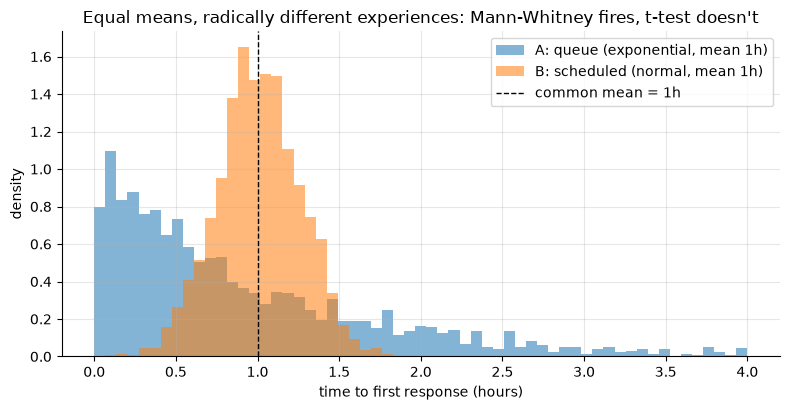

In [8]:
fig, ax = plt.subplots()
bins = np.linspace(0, 4, 60)
ax.hist(tta_a, bins=bins, alpha=0.55, density=True, label="A: queue (exponential, mean 1h)")
ax.hist(tta_b, bins=bins, alpha=0.55, density=True, label="B: scheduled (normal, mean 1h)")
ax.axvline(1.0, color="black", ls="--", lw=1, label="common mean = 1h")
ax.set_xlabel("time to first response (hours)")
ax.set_ylabel("density")
ax.set_title("Equal means, radically different experiences: Mann-Whitney fires, t-test doesn't")
ax.legend()
plt.show()

Mann–Whitney is enormously significant because a random ticket from A beats (is faster
than) a random ticket from B about 64% of the time — even though the *average* wait is
identical, and the t-test rightly sees nothing. Neither test is "wrong"; they answer
different questions.

**Common misuses to call out in interviews:**

1. *"Data wasn't normal, so we ran Mann–Whitney and the medians differ significantly."*
   Without the shift assumption, MW rejection does **not** license a median claim — you can
   build distributions with *equal medians* where MW still rejects (skewness alone does it).
   The honest conclusion is about stochastic ordering: report the probability of
   superiority $\hat{P}(X>Y)$ (the effect size MW actually estimates — it's the AUC).
2. *Using MW as a drop-in for the t-test on revenue.* If the business decision rides on
   the **mean** (total revenue = mean × users), a rank test answers the wrong question:
   MW can be significant in the *opposite direction* of the mean difference.
3. *Trusting MW under unequal variances.* The MW null is "no stochastic dominance," but
   its classic variance formula assumes identical distributions; under unequal spreads it
   can over-reject that weaker null. **Brunner–Munzel** (above) tests
   $P(X>Y)=\tfrac12$ without that assumption — prefer it when groups differ in shape.

## 4. Proportion tests: z, χ², and lift confidence intervals

For a conversion A/B test the two-proportion z-test (pooled) and the 2×2 Pearson χ²
test (without continuity correction) are **the same test**: $z^2 = \chi^2$ and the
p-values match exactly. Knowing this saves you from "should I use a chi-square or a
z-test?" — it's one test wearing two outfits.

In [9]:
n_ctrl = n_trt = 10_000
conv_ctrl, conv_trt = 512, 583          # bookings out of sessions

z_stat, p_z = proportions_ztest(
    count=np.array([conv_trt, conv_ctrl]), nobs=np.array([n_trt, n_ctrl])
)
table = np.array([[conv_trt, n_trt - conv_trt],
                  [conv_ctrl, n_ctrl - conv_ctrl]])
chi2_res = stats.chi2_contingency(table, correction=False)

print(f"z = {z_stat:.4f}   z² = {z_stat**2:.4f}   χ² = {chi2_res.statistic:.4f}")
print(f"p (z-test)  = {p_z:.6f}")
print(f"p (chi²)    = {chi2_res.pvalue:.6f}")
print(f"identical?  z²-χ² = {z_stat**2 - chi2_res.statistic:.2e},"
      f"  Δp = {p_z - chi2_res.pvalue:.2e}")

z = 2.2069   z² = 4.8703   χ² = 4.8703
p (z-test)  = 0.027323
p (chi²)    = 0.027323
identical?  z²-χ² = -7.11e-15,  Δp = 6.59e-17


### Confidence intervals the business can use: absolute and relative lift

A p-value alone is a terrible experiment readout. Report the lift with uncertainty, in
both units stakeholders use:

- **Absolute lift** $\hat p_T - \hat p_C$: Wald interval with *unpooled* SE. (Nuance worth
  knowing: the test uses the pooled SE, the CI the unpooled one — so p-values and CIs can
  disagree right at the boundary.)
- **Relative lift** $\hat p_T/\hat p_C - 1$: the ratio's sampling distribution is
  right-skewed (a ratio of noisy things), so build the CI on the **log scale** and
  exponentiate: $\log RR \pm z_{\alpha/2}\sqrt{\frac{1-p_C}{n_C p_C} + \frac{1-p_T}{n_T p_T}}$.
  A symmetric Wald CI directly on the ratio is both miscalibrated and can cover
  impossible negative values. (General-purpose ratio machinery — the delta method — is in
  [../02_ab_testing/05_ratio_metrics_delta_method.ipynb](../02_ab_testing/05_ratio_metrics_delta_method.ipynb).)

In [10]:
p_c, p_t = conv_ctrl / n_ctrl, conv_trt / n_trt
z975 = stats.norm.ppf(0.975)

# absolute lift, unpooled Wald
abs_lift = p_t - p_c
se_abs = np.sqrt(p_c * (1 - p_c) / n_ctrl + p_t * (1 - p_t) / n_trt)
ci_abs = abs_lift - z975 * se_abs, abs_lift + z975 * se_abs

# relative lift via log(risk ratio)
rr = p_t / p_c
se_log_rr = np.sqrt((1 - p_c) / (n_ctrl * p_c) + (1 - p_t) / (n_trt * p_t))
ci_rr = np.exp(np.log(rr) - z975 * se_log_rr), np.exp(np.log(rr) + z975 * se_log_rr)

print(f"conversion: control {p_c:.2%}  ->  treatment {p_t:.2%}\n")
print(f"absolute lift : {abs_lift * 100:+.2f}pp   95% CI [{ci_abs[0] * 100:+.2f}pp, {ci_abs[1] * 100:+.2f}pp]")
print(f"relative lift : {rr - 1:+.1%}    95% CI [{ci_rr[0] - 1:+.1%}, {ci_rr[1] - 1:+.1%}]")

conversion: control 5.12%  ->  treatment 5.83%

absolute lift : +0.71pp   95% CI [+0.08pp, +1.34pp]
relative lift : +13.9%    95% CI [+1.5%, +27.8%]


Note the asymmetry of the relative-lift interval, and how humbling it is: a "significant"
+13.9% relative lift is statistically compatible with anything from ~+1.5% to ~+28%. That
range — not the p-value — is what should drive the rollout conversation.

### Small-n behavior: when the normal approximation falls apart

The z/χ² test is a large-sample approximation to a **discrete** problem. With small n or
rare conversions, the p-value can only take a handful of values, so the actual type-I
error drifts away from the nominal α — sometimes below it, at other n/p combinations
above it — and oscillates as n changes.

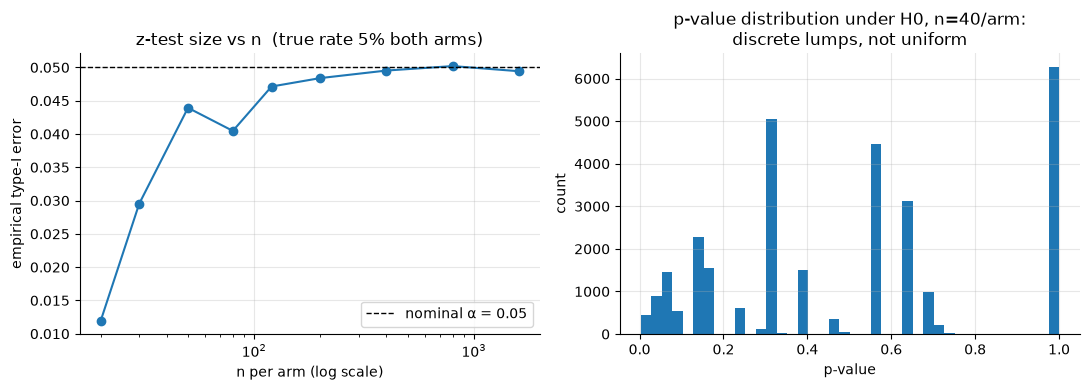

 n per arm  empirical size
        20          0.0119
        30          0.0295
        50          0.0439
        80          0.0405
       120          0.0471
       200          0.0484
       400          0.0495
       800          0.0502
      1600          0.0494


In [11]:
def prop_ztest_pvalues(n_per_arm, p0, n_sims=30_000):
    """Simulate two-sided pooled z-test p-values under H0: both arms convert at p0."""
    c = rng.binomial(n_per_arm, p0, n_sims)
    t = rng.binomial(n_per_arm, p0, n_sims)
    pooled = (c + t) / (2 * n_per_arm)
    se = np.sqrt(pooled * (1 - pooled) * 2 / n_per_arm)
    z = np.zeros(n_sims)
    ok = se > 0
    z[ok] = (t[ok] - c[ok]) / n_per_arm / se[ok]
    return 2 * stats.norm.sf(np.abs(z))

p0 = 0.05
ns = np.array([20, 30, 50, 80, 120, 200, 400, 800, 1600])
sizes = np.array([(prop_ztest_pvalues(n, p0) < 0.05).mean() for n in ns])

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(ns, sizes, "o-")
axes[0].axhline(0.05, color="black", ls="--", lw=1, label="nominal α = 0.05")
axes[0].set_xscale("log")
axes[0].set_xlabel("n per arm (log scale)")
axes[0].set_ylabel("empirical type-I error")
axes[0].set_title(f"z-test size vs n  (true rate {p0:.0%} both arms)")
axes[0].legend()

axes[1].hist(prop_ztest_pvalues(40, p0), bins=40)
axes[1].set_xlabel("p-value")
axes[1].set_ylabel("count")
axes[1].set_title("p-value distribution under H0, n=40/arm:\ndiscrete lumps, not uniform")
plt.show()

print(pd.DataFrame({"n per arm": ns, "empirical size": sizes.round(4)}).to_string(index=False))

At n=20–50 per arm with a 5% base rate the test's real false-positive rate can drift far
from 5% (here it *under*-rejects badly at the smallest n — expected conversions per arm are
~1–3, and the discrete p-value distribution just misses the 0.05 threshold; at other n/p
combinations it overshoots instead). Either way, the advertised α is fiction.

For small samples, use an **exact test**. Fisher's exact test is the household name but is
*conservative* (it conditions on the margins); **Boschloo's** uncontested-margin exact test
dominates it in power while keeping the type-I guarantee.

In [12]:
pilot = np.array([[9, 31],     # treatment: 9/40 converted
                  [3, 37]])    # control:   3/40 converted
z_pilot, p_z_pilot = proportions_ztest(count=pilot[:, 0], nobs=pilot.sum(axis=1))
fisher = stats.fisher_exact(pilot)
boschloo = stats.boschloo_exact(pilot, alternative="two-sided")

print("pilot: 9/40 vs 3/40 conversions")
print(f"  z-test (approx)   p = {p_z_pilot:.4f}   <- approximation, no guarantee here")
print(f"  Fisher exact      p = {fisher.pvalue:.4f}   <- valid but conservative")
print(f"  Boschloo exact    p = {boschloo.pvalue:.4f}   <- valid, more powerful than Fisher")

pilot: 9/40 vs 3/40 conversions
  z-test (approx)   p = 0.0603   <- approximation, no guarantee here
  Fisher exact      p = 0.1149   <- valid but conservative
  Boschloo exact    p = 0.0663   <- valid, more powerful than Fisher


## 5. Effect sizes: statistical vs practical significance

A p-value mixes two things you must keep separate: the size of the effect and the size of
the sample. At large n, *everything* is significant. The senior habit is to lead with the
**effect size and its CI**, in units the business plans with:

- **Raw / business units first**: +0.4 minutes of watch time, +0.2pp conversion, +$0.05
  revenue per user. Multiply by traffic to get the annualized impact — that's the number
  that competes with engineering cost and roadmap opportunity cost.
- **Cohen's d** = (mean difference) / (pooled SD) — useful as a *scale-free sanity check*
  and for power planning, not as a headline. Rules of thumb (0.2 small / 0.5 medium /
  0.8 large) come from psychology; in mature online products, real effects are routinely
  d < 0.05, so judge d against *your* domain's history, not Cohen's labels.

Demonstration: two million users, a real but microscopic effect, and the p-value screams.

In [13]:
def cohens_d(x, y):
    nx, ny = len(x), len(y)
    sp = np.sqrt(((nx - 1) * x.var(ddof=1) + (ny - 1) * y.var(ddof=1)) / (nx + ny - 2))
    return (x.mean() - y.mean()) / sp

n_big = 1_000_000                                   # per arm
watch_ctrl = rng.normal(120.0, 60.0, n_big)         # weekly watch minutes
watch_trt = rng.normal(120.6, 60.0, n_big)          # true effect: +0.6 min  (d = 0.01)

res_big = stats.ttest_ind(watch_trt, watch_ctrl, equal_var=False)
diff = watch_trt.mean() - watch_ctrl.mean()
se_big = np.sqrt(watch_trt.var(ddof=1) / n_big + watch_ctrl.var(ddof=1) / n_big)
d_big = cohens_d(watch_trt, watch_ctrl)

print(f"n = {n_big:,} per arm")
print(f"p-value      = {res_big.pvalue:.2e}   (p < 1e-6 by a huge margin)")
print(f"effect       = {diff:+.3f} min/week   95% CI [{diff - 1.96 * se_big:+.3f}, {diff + 1.96 * se_big:+.3f}]")
print(f"relative     = {diff / watch_ctrl.mean():+.2%} of the {watch_ctrl.mean():.0f}-min baseline")
print(f"Cohen's d    = {d_big:.4f}")

n = 1,000,000 per arm
p-value      = 2.93e-12   (p < 1e-6 by a huge margin)
effect       = +0.592 min/week   95% CI [+0.426, +0.758]
relative     = +0.49% of the 120-min baseline
Cohen's d    = 0.0099


p is thousands of times smaller than 10⁻⁶ — and the effect is **half a percent** of
baseline, d ≈ 0.01, with a CI so tight we *know* the effect is tiny. "Significant" here
means only: the sample was big enough to resolve it. Whether +0.6 min/week justifies
shipping depends on maintenance cost, added
latency or complexity, and what else the team could build — a product judgment the p-value
cannot make. This is why experiment templates should carry a pre-registered **minimum
effect of interest**, and why power is planned against that MDE, not against "any
nonzero effect" ([../02_ab_testing/02_power_mde_sample_size.ipynb](../02_ab_testing/02_power_mde_sample_size.ipynb)).

The mirror image also matters: at small n, a *huge* point estimate with p = 0.08 is often
more interesting than this microscopically-certain triviality. Estimation beats binary
verdicts.

## 6. What p-values are — and are not

A p-value is the probability, **computed assuming H0 is true**, of data at least as
extreme as observed: $P(\text{data this extreme} \mid H_0)$. It is *not* $P(H_0 \mid
\text{data})$ — flipping that conditional is the transposed-conditional fallacy, and it's
the most common p-value error in industry.

As a random variable, the p-value has a signature behavior worth having seen with your own
eyes:

- Under H0 (for a continuous, correctly calibrated test), **p is uniform on [0, 1]**.
  p = 0.93 and p = 0.03 are equally probable under the null. This uniformity is exactly
  what "α-level test" means — and it's what peeking destroys
  ([../02_ab_testing/04_peeking_sequential.ipynb](../02_ab_testing/04_peeking_sequential.ipynb)).
- Under an alternative, the distribution piles up near 0 — the more power, the harder it
  piles.

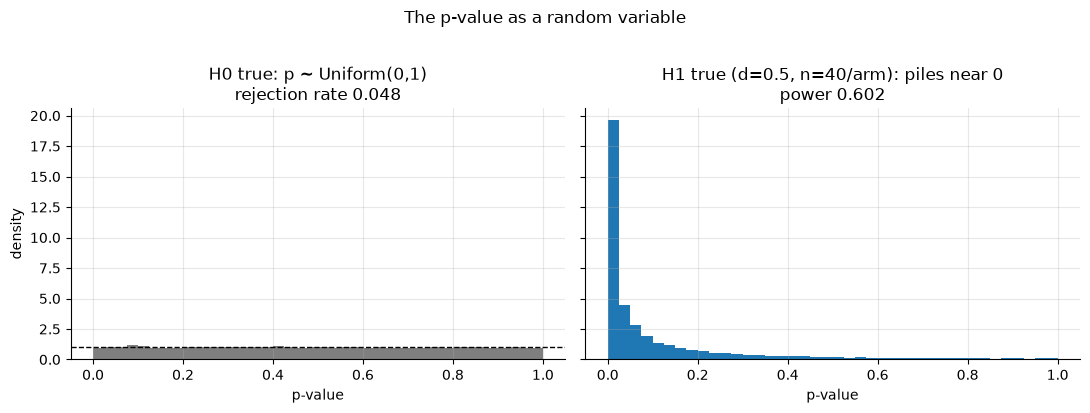

In [14]:
n_sims, n_pv = 20_000, 40
null_p = stats.ttest_ind(
    rng.normal(0.0, 1.0, (n_sims, n_pv)), rng.normal(0.0, 1.0, (n_sims, n_pv)), axis=1
).pvalue
alt_p = stats.ttest_ind(
    rng.normal(0.5, 1.0, (n_sims, n_pv)), rng.normal(0.0, 1.0, (n_sims, n_pv)), axis=1
).pvalue

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
axes[0].hist(null_p, bins=40, density=True, color="tab:gray")
axes[0].axhline(1.0, color="black", ls="--", lw=1)
axes[0].set_title(f"H0 true: p ~ Uniform(0,1)\nrejection rate {np.mean(null_p < 0.05):.3f}")
axes[1].hist(alt_p, bins=40, density=True, color="tab:blue")
axes[1].set_title(f"H1 true (d=0.5, n=40/arm): piles near 0\npower {np.mean(alt_p < 0.05):.3f}")
for ax in axes:
    ax.set_xlabel("p-value")
axes[0].set_ylabel("density")
fig.suptitle("The p-value as a random variable", y=1.02)
plt.show()

### Why p ≠ P(H0 | data): base rates decide

To turn a p-value into "probability the effect is real" you need a prior — the base rate
of true effects in your experiment pipeline. Mature experimentation programs report that
only ~10–20% of ideas move their primary metric. Let's simulate a realistic portfolio:
10% of experiments have a real effect (d = 0.4, run at 80% power), 90% are nulls, all
tested at α = 0.05.

In [15]:
n_exp = 50_000
base_rate = 0.10
n_per_arm, d_true = 100, 0.4                      # ~80% power at alpha=0.05

is_real = rng.random(n_exp) < base_rate
ncp = d_true * np.sqrt(n_per_arm / 2)             # noncentrality of the two-sample z
z_exp = rng.normal(np.where(is_real, ncp, 0.0), 1.0)
p_exp = 2 * stats.norm.sf(np.abs(z_exp))

sig = p_exp < 0.05
barely = (p_exp >= 0.01) & (p_exp < 0.05)
fdr_sig = np.mean(~is_real[sig])
fdr_barely = np.mean(~is_real[barely])

print(f"experiments: {n_exp:,} | true-effect base rate {base_rate:.0%} | "
      f"power {np.mean(p_exp[is_real] < 0.05):.2f}\n")
print(f"P(no real effect | p < 0.05)        = {fdr_sig:.2f}")
print(f"P(no real effect | 0.01 ≤ p < 0.05) = {fdr_barely:.2f}")

experiments: 50,000 | true-effect base rate 10% | power 0.81

P(no real effect | p < 0.05)        = 0.35
P(no real effect | 0.01 ≤ p < 0.05) = 0.62


Read those numbers again: in this (realistic) regime, a significant result is a false
alarm about **1 time in 3**, and a *barely* significant result (p between 0.01 and 0.05)
is **more likely to be a false alarm than not** (~62%). Yet the p-value printed 0.03.
"p = 0.03" and "97% sure it's real" are different claims, and the gap between them is the
base rate.

Other traps to have loaded, stated precisely:

- **1 − p is not the probability of replication.** An exact replica of a study with
  p = 0.05 has roughly a coin-flip chance of reaching p < 0.05 again (power ≈ 50% at the
  observed effect size).
- **p depends on n.** A p-value is not an effect size; comparing p-values across
  experiments with different n compares nothing meaningful.
- **Nonsignificance is not equivalence.** "p = 0.4" never demonstrates "no effect" — if
  you need to *demonstrate absence*, run an equivalence test (TOST) against a
  pre-specified margin.
- If you actually want P(effect real | data), that's a Bayesian quantity — see
  [../06_bayesian_methods/01_bayesian_ab_testing.ipynb](../06_bayesian_methods/01_bayesian_ab_testing.ipynb).

## 7. Pitfalls

### Pitfall 1: pre-testing assumptions, then choosing the test

The textbook two-stage recipe — "F-test (or Levene) for equal variances; if not rejected
use Student, else Welch" — is broken. The pre-test has low power exactly where it matters
(small n), so the branch condition correlates with the data, and the resulting compound
procedure has a type-I error that is neither Student's nor Welch's — and above nominal.
The same criticism applies to "Shapiro–Wilk for normality, then t-test vs Mann–Whitney"
(worse, since the fallback tests a different hypothesis entirely).

In [16]:
n_sims = 40_000
n1_p, sd1_p, n2_p, sd2_p = 10, 1.6, 40, 1.0        # H0 true: equal means, unequal SDs

a = rng.normal(0.0, sd1_p, (n_sims, n1_p))
b = rng.normal(0.0, sd2_p, (n_sims, n2_p))
p_stud = stats.ttest_ind(a, b, axis=1, equal_var=True).pvalue
p_wel = stats.ttest_ind(a, b, axis=1, equal_var=False).pvalue

F = a.var(axis=1, ddof=1) / b.var(axis=1, ddof=1)
p_F = 2 * np.minimum(stats.f.sf(F, n1_p - 1, n2_p - 1), stats.f.cdf(F, n1_p - 1, n2_p - 1))
p_two_stage = np.where(p_F < 0.05, p_wel, p_stud)   # pre-test decides the branch

print(f"H0 true, n={n1_p}/{n2_p}, sd={sd1_p}/{sd2_p}  (nominal α = 0.05)")
print(f"  Student always     : type-I error = {(p_stud < 0.05).mean():.3f}")
print(f"  Welch always       : type-I error = {(p_wel < 0.05).mean():.3f}")
print(f"  pre-test two-stage : type-I error = {(p_two_stage < 0.05).mean():.3f}"
      f"   (pre-test missed the variance difference {(p_F >= 0.05).mean():.0%} of the time)")

H0 true, n=10/40, sd=1.6/1.0  (nominal α = 0.05)
  Student always     : type-I error = 0.131
  Welch always       : type-I error = 0.051
  pre-test two-stage : type-I error = 0.083   (pre-test missed the variance difference 52% of the time)


The pre-test failed to detect the (real, 2.6x) variance difference about **half the
time**, so the two-stage procedure inherited much of Student's inflation — its real α is
roughly 8–9%, neither test's advertised 5%. Decide your test from the *design*, before
data: Welch for means, always.

### Pitfall 2: one-sided vs two-sided honesty

A one-sided test at α = 0.05 puts all 5% of rejection mass in one pre-declared tail. The
dishonest version — run two-sided, see the sign, then report the one-sided p "because we
only cared about improvement" — is just halving your p-value after peeking at the data.
Under the null it rejects at 2α:

In [17]:
n_sims_os, n_os = 40_000, 50
p_two_sided = stats.ttest_ind(
    rng.normal(0.0, 1.0, (n_sims_os, n_os)), rng.normal(0.0, 1.0, (n_sims_os, n_os)), axis=1
).pvalue
p_posthoc_one_sided = p_two_sided / 2   # 'one-sided in whichever direction looks good'

print(f"H0 true, nominal α = 0.05:")
print(f"  honest two-sided                rejects {(p_two_sided < 0.05).mean():.3f}")
print(f"  post-hoc one-sided (cheating)   rejects {(p_posthoc_one_sided < 0.05).mean():.3f}"
      "   <- exactly doubled")

H0 true, nominal α = 0.05:
  honest two-sided                rejects 0.049
  post-hoc one-sided (cheating)   rejects 0.100   <- exactly doubled


One-sided tests are legitimate when the direction is fixed **before** data collection and
the other direction genuinely triggers the same decision as "no effect" (e.g. a
non-inferiority launch gate). The tell of legitimacy is a paper trail: the sidedness is in
the experiment plan, not in the analysis notebook. If an interviewer asks "can I use a
one-sided test to hit significance?", the answer is: you may use one-sided α = 0.05 *if
pre-registered*; switching sidedness (or halving p) after seeing results is α-inflation.

### Pitfall 3: reading "not significant" as "no effect"

An underpowered experiment can't distinguish a meaningful win from a meaningful loss. The
CI — not the p-value — says what the data rule out:

In [18]:
n_small = 20
aov_ctrl = rng.normal(100.0, 30.0, n_small)     # average order value, $
aov_trt = rng.normal(103.0, 30.0, n_small)      # true effect: +3% — worth real money

res_small = stats.ttest_ind(aov_trt, aov_ctrl, equal_var=False)
ci_small = res_small.confidence_interval(0.95)
diff_small = aov_trt.mean() - aov_ctrl.mean()

# n per arm needed for 80% power to detect +$3 with sd=$30 (two-sided alpha=0.05)
n_needed = 2 * (30 / 3) ** 2 * (stats.norm.ppf(0.975) + stats.norm.ppf(0.80)) ** 2

print(f"observed diff = ${diff_small:+.2f},  p = {res_small.pvalue:.2f}")
print(f"95% CI: [${ci_small.low:+.1f}, ${ci_small.high:+.1f}]  "
      f"(i.e. {ci_small.low / 100:+.0%} to {ci_small.high / 100:+.0%} of a $100 AOV)")
print(f"\nverdict: inconclusive — the CI contains both business-critical losses and wins.")
print(f"n per arm for 80% power at +$3: ~{n_needed:,.0f}  (we had {n_small})")

observed diff = $+15.15,  p = 0.13
95% CI: [$-4.8, $+35.1]  (i.e. -5% to +35% of a $100 AOV)

verdict: inconclusive — the CI contains both business-critical losses and wins.
n per arm for 80% power at +$3: ~1,570  (we had 20)


With 20 orders per arm the interval spans roughly −5% to +35% of order value: compatible
with a meaningful loss *and* with an implausibly gigantic win (the true effect is +3%).
Reporting this as "not significant, no effect of the new checkout" would be malpractice;
the correct readout is "underpowered, need ~1,570 per arm" — power
math in [../02_ab_testing/02_power_mde_sample_size.ipynb](../02_ab_testing/02_power_mde_sample_size.ipynb).
For the industrial-scale version of these pitfalls (p-hacking, multiple looks, subgroup
fishing) see [04_statistical_traps.ipynb](./04_statistical_traps.ipynb).

## 8. Interview corner

**Q1. Explain a p-value to a PM.**
Strong answer: skip the definition-first instinct. "Assume the feature truly does nothing.
The p-value is the chance we'd still see a difference at least this large, just from
random user-to-user noise. p = 0.03 means: if the feature were dead, only ~3% of A/B tests
like ours would look this good by luck." Then immediately add what it is *not*: "It is not
the probability the feature works — that depends on how often our ideas work in general."
Bonus points for pivoting to the CI: "the more useful number is: lift between X and Y."

**Q2. What are the two-sample t-test's assumptions, and what actually happens when each is
violated?**
Strong answer, ordered by importance: (1) *Independence* — the big one; correlated units
(same user twice, network effects, clustered rollouts) silently shrink the effective n and
wreck the SE; no amount of n fixes it (see
[../02_ab_testing/05_ratio_metrics_delta_method.ipynb](../02_ab_testing/05_ratio_metrics_delta_method.ipynb)).
(2) *Equal variances* — only assumed by Student's version; violation with unbalanced n
distorts size badly (Section 1); use Welch. (3) *Normality* — least important at scale:
the CLT covers the sample means at moderate n; matters for small n with heavy tails,
where permutation tests are the safe harbor.

**Q3. Your metric is skewed, so a colleague switches to Mann–Whitney and reports "median
revenue increased significantly." Critique.**
Strong answer: MW tests stochastic dominance ($P(X>Y) = 1/2$), not medians; the median
interpretation needs an identical-shape shift assumption that skewed revenue data won't
meet. Also, if the decision rides on total revenue, the mean is the decision-relevant
functional and a rank test can even disagree with it in direction. Better options: t-test
on the mean (CLT), permutation test with a studentized mean statistic, or report
$\hat P(X>Y)$ honestly as the effect. Mention Brunner–Munzel for unequal shapes.

**Q4. p = 3×10⁻⁹ on a +0.2% revenue lift at n = 5M. Ship it?**
Strong answer: significance is settled; the question is now purely economic. Compute the
annualized value of +0.2% against implementation, latency, complexity, and opportunity
cost. Check the CI's lower bound in dollars; check heterogeneity (is the tiny average a
mix of +2% somewhere and −1.8% elsewhere?); check guardrail metrics; consider novelty
decay. A senior answer also flags the reverse error: don't demand p < 0.05 *and then*
ignore effect size — pre-register a minimum effect of interest so this question is
answered before launch.

**Q5. When would you use a permutation test over a t-test, and what null does it test?**
Strong answer: small samples, ugly distributions, or nonstandard statistics (medians,
quantiles, trimmed means). It's exact under the sharp null of exchangeability (identical
distributions), which is stronger than "equal means" — so under unequal variances permute
a studentized statistic. Costs: computation, and it gives a test, not a CI (bootstrap for
that).

**Q6. Why do proportion z-test and chi-square give the same answer? When do both fail?**
Strong answer: on a 2×2 table, Pearson's χ² statistic is algebraically the square of the
pooled two-proportion z; identical p-values. Both are normal approximations that fail at
small n / rare events, where the discrete sampling distribution makes the real α drift
from nominal — switch to exact tests (Fisher is valid but conservative; Boschloo is
uniformly more powerful).

**Q7. The experiment platform shows p = 0.04. The PM says "so there's a 96% chance the
feature works." Respond.**
Strong answer: that's the transposed conditional. P(effect | data) needs the base rate of
winning ideas: at a 10% base rate and 80% power, ~1/3 of p < 0.05 results are false alarms,
and among *barely* significant ones most are (Section 6). If the PM wants "probability it
works," offer a Bayesian analysis with an explicit prior.

**Q8. Your teammate reruns the analysis one-sided "since we only care about improvement"
and the result becomes significant. OK?**
Strong answer: not post hoc — choosing sidedness after seeing the direction doubles the
false-positive rate (Section 7). One-sided is fine only if pre-registered and the adverse
direction truly maps to the same decision as null. In that regime, also be honest that
harmful effects will be reported as "not significant" by design.

## 9. Key takeaways

- **Welch by default.** Student's t with unequal variances + unequal n can reject a true
  null ~28% of the time (noisy small group) or ~0.05% (noisy big group). Welch costs
  nothing when variances are equal.
- **Never pre-test assumptions to pick the test.** Two-stage procedures (F-test → t-test
  choice) have distorted error rates; choose the analysis from the design.
- **Permutation tests are exact** under exchangeability and work for any statistic —
  but the null is "identical distributions," so studentize the statistic when spreads may
  differ. Tests come from permutation; CIs come from the bootstrap.
- **Mann–Whitney tests $P(X>Y)=\tfrac12$**, not medians and not means. Report the
  probability of superiority; use Brunner–Munzel when shapes differ; don't use rank tests
  when the decision rides on the mean.
- **z² = χ²** on a 2×2 table — one test, two names. Small n breaks both: go exact
  (Boschloo over Fisher for power).
- **Report lift with CIs in business units** — absolute (pp) and relative (log-scale CI,
  asymmetric). The p-value is the least informative number in the readout.
- **p is uniform under H0** and piles near 0 under alternatives; p is
  P(data | H0)-flavored, never P(H0 | data). With a 10% base rate of real effects, ~1/3 of
  p < 0.05 results are false alarms — and most p ∈ [0.01, 0.05] results are.
- **Statistical ≠ practical significance.** At n = 10⁶ per arm, d = 0.01 drives p far
  below 10⁻⁶; pre-register a minimum effect of interest so "significant but tiny" has an
  agreed answer.
- **Nonsignificant ≠ no effect.** Read the CI; if you must demonstrate absence, use
  equivalence testing (TOST).
- **Sidedness is a design choice**, made before data. Halving p after seeing the sign is
  α-inflation, full stop.

## 10. Exercises

### Exercise 1 — Fix the permutation test under unequal variances

Section 2 warned that the mean-difference permutation test tests the *sharp* null. Make
that concrete: simulate H0-in-means-only data — group X ~ Normal(0, 3) with n=10, group
Y ~ Normal(0, 1) with n=50 (equal means, very unequal spreads) — and estimate the type-I
error of (a) the raw mean-difference permutation test and (b) a permutation test that uses
the **Welch t-statistic** as its statistic. Explain the mechanism behind the difference.

In [19]:
# --- Solution ---
def welch_t_stat(a, b):
    va = a.var(axis=-1, ddof=1)
    vb = b.var(axis=-1, ddof=1)
    return (a.mean(axis=-1) - b.mean(axis=-1)) / np.sqrt(va / a.shape[-1] + vb / b.shape[-1])


def perm_size(stat, n_datasets=300, n_perm=999):
    rejections = 0
    for _ in range(n_datasets):
        x = rng.normal(0.0, 3.0, 10)     # small AND noisy
        y = rng.normal(0.0, 1.0, 50)     # large and quiet
        _, p, _ = perm_test(x, y, stat, n_perm=n_perm)
        rejections += p <= 0.05
    return rejections / n_datasets

size_raw = perm_size(mean_diff)
size_studentized = perm_size(welch_t_stat)

print(f"equal means, unequal variances (n=10 sd=3 vs n=50 sd=1), α = 0.05:")
print(f"  permutation on raw mean difference : type-I error ≈ {size_raw:.3f}")
print(f"  permutation on Welch t statistic   : type-I error ≈ {size_studentized:.3f}")
print("""
Mechanism: permuting labels mixes high- and low-variance observations across groups, so
the permutation null distribution of the *raw* difference reflects a pooled variance —
too small for the noisy n=10 group, exactly Student's disease. The Welch t statistic
rescales each permuted sample by its own variance, restoring approximate pivotality.""")

equal means, unequal variances (n=10 sd=3 vs n=50 sd=1), α = 0.05:
  permutation on raw mean difference : type-I error ≈ 0.253
  permutation on Welch t statistic   : type-I error ≈ 0.070

Mechanism: permuting labels mixes high- and low-variance observations across groups, so
the permutation null distribution of the *raw* difference reflects a pooled variance —
too small for the noisy n=10 group, exactly Student's disease. The Welch t statistic
rescales each permuted sample by its own variance, restoring approximate pivotality.


### Exercise 2 — Prove z² = χ² numerically

Generate 200 random 2×2 conversion tables (varying n and rates), and verify that the
pooled two-proportion z-test and Pearson's χ² (no continuity correction) agree to machine
precision, in both statistic (z² vs χ²) and p-value.

In [20]:
# --- Solution ---
max_stat_gap, max_p_gap = 0.0, 0.0
for _ in range(200):
    n1_e = int(rng.integers(50, 500))
    n2_e = int(rng.integers(50, 500))
    c1 = int(np.clip(rng.binomial(n1_e, rng.uniform(0.05, 0.5)), 1, n1_e - 1))
    c2 = int(np.clip(rng.binomial(n2_e, rng.uniform(0.05, 0.5)), 1, n2_e - 1))
    z_e, p_ze = proportions_ztest(count=np.array([c1, c2]), nobs=np.array([n1_e, n2_e]))
    chi_e = stats.chi2_contingency(
        np.array([[c1, n1_e - c1], [c2, n2_e - c2]]), correction=False
    )
    max_stat_gap = max(max_stat_gap, abs(z_e**2 - chi_e.statistic))
    max_p_gap = max(max_p_gap, abs(p_ze - chi_e.pvalue))

print(f"200 random tables:  max |z² − χ²| = {max_stat_gap:.2e},  max |Δp| = {max_p_gap:.2e}")
print("Identical to numerical precision: one test, two names.")

200 random tables:  max |z² − χ²| = 8.53e-14,  max |Δp| = 4.08e-15
Identical to numerical precision: one test, two names.


### Exercise 3 — Wald vs Wilson coverage for a proportion

The Wald interval $\hat p \pm z\sqrt{\hat p(1-\hat p)/n}$ is what everyone writes first,
and it's the worst mainstream choice. For n = 50, compute the **exact** coverage of the
95% Wald and Wilson intervals for every true p on a grid from 0.01 to 0.5 (no simulation
needed — sum binomial probabilities over the k whose interval covers p) and plot both.

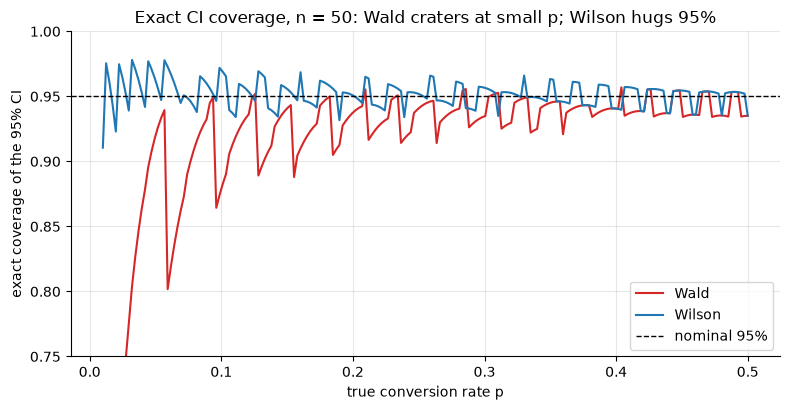

minimum coverage on the grid — Wald: 0.395   Wilson: 0.911
Use Wilson (statsmodels: proportion_confint(method='wilson')) for proportions,
especially with small n or rates near 0 — exactly where conversion data lives.


In [21]:
# --- Solution ---
n_cov = 50
z_c = stats.norm.ppf(0.975)
k = np.arange(n_cov + 1)
phat = k / n_cov

# Wald limits for each possible outcome k
wald_half = z_c * np.sqrt(phat * (1 - phat) / n_cov)
wald_lo, wald_hi = phat - wald_half, phat + wald_half

# Wilson limits for each possible outcome k
denom = 1 + z_c**2 / n_cov
center = (phat + z_c**2 / (2 * n_cov)) / denom
wil_half = (z_c / denom) * np.sqrt(phat * (1 - phat) / n_cov + z_c**2 / (4 * n_cov**2))
wil_lo, wil_hi = center - wil_half, center + wil_half

p_grid = np.linspace(0.01, 0.5, 200)
pmf = stats.binom.pmf(k[None, :], n_cov, p_grid[:, None])        # (grid, k)
cov_wald = (pmf * ((wald_lo[None, :] <= p_grid[:, None]) &
                   (p_grid[:, None] <= wald_hi[None, :]))).sum(axis=1)
cov_wilson = (pmf * ((wil_lo[None, :] <= p_grid[:, None]) &
                     (p_grid[:, None] <= wil_hi[None, :]))).sum(axis=1)

fig, ax = plt.subplots()
ax.plot(p_grid, cov_wald, label="Wald", color="tab:red")
ax.plot(p_grid, cov_wilson, label="Wilson", color="tab:blue")
ax.axhline(0.95, color="black", ls="--", lw=1, label="nominal 95%")
ax.set_ylim(0.75, 1.0)
ax.set_xlabel("true conversion rate p")
ax.set_ylabel("exact coverage of the 95% CI")
ax.set_title(f"Exact CI coverage, n = {n_cov}: Wald craters at small p; Wilson hugs 95%")
ax.legend()
plt.show()

print(f"minimum coverage on the grid — Wald: {cov_wald.min():.3f}   Wilson: {cov_wilson.min():.3f}")
print("Use Wilson (statsmodels: proportion_confint(method='wilson')) for proportions,")
print("especially with small n or rates near 0 — exactly where conversion data lives.")

---
**Next:** [03_regression_the_workhorse.ipynb](./03_regression_the_workhorse.ipynb) — where
t-tests become a special case of regression, and covariates start earning their keep.